# 🧠 Automated Dataset Insight & Exploratory Data Analysis (EDA) Pipeline
### OpenNeuro Dataset `ds007526`: PD-EEG Locomotion & Resting-State
**Author:** Antigravity AI Assistant & Research Team  
**Platform:** Kaggle (100% Automated Execution)  
**Target:** Biomedical Signal Processing & BCI Cross-Subject Gait Decoding

---
### 📌 এই নোটবুকের উদ্দেশ্য (What this Notebook Automates):
1. **স্বয়ংক্রিয় পাথ ডিটেকশন (Auto-Discovery):** Kaggle-এর `/kaggle/input`-এ ডেটাসেট যে নামেই থাকুক না কেন, এটি স্বয়ংক্রিয়ভাবে খুঁজে বের করবে।
2. **ক্লিনিক্যাল কোহর্ট অ্যানালাইসিস (Clinical Insights):** পারকিনসন রোগী (PD) বনাম সুস্থ কন্ট্রোল (HC)-এর বয়স, লিঙ্গ ও রোগের ডিস্ট্রিবিউশন বিশ্লেষণ।
3. **রেকর্ডিং ইনভেন্টরি ও সিগন্যাল কোয়ালিটি:** মোট ফাইল, স্যাম্পলিং রেট, চ্যানেল সংখ্যা ও রেকর্ডিং টাইমের পূর্ণাঙ্গ অডিট।
4. **হাঁটা বনাম রেস্ট সিগন্যাল ভিজ্যুয়ালাইজেশন:** একই মানুষের Rest বনাম Walk অবস্থার ব্রেন সিগন্যালের সরাসরি তুলনা।
5. **ফ্রিকোয়েন্সি ও ব্যান্ডপাওয়ার বিশ্লেষণ (PSD):** Delta, Theta, Alpha, Beta, Gamma ব্যান্ডের পাওয়ার ক্যালকুলেশন ও আর্টফ্যাক্ট সার্জনীতি।
6. **সেন্সর মন্টেজ ও টোপোম্যাপ:** মাথার খুলিতে ৬০টি ইলেকট্রোড ও ৪টি চোখের চ্যানেলের অবস্থান প্লট করা।
7. **ফলাফল সংরক্ষণ:** সব গ্রাফ ও টেবিল স্বয়ংক্রিয়ভাবে `/kaggle/working/dataset_insights/` ফোল্ডারে সেভ হবে।


## 1. Environment Setup & Library Installation


In [1]:
# Automatically install required neuro-imaging & visualization packages quietly
!pip install -q mne seaborn scipy matplotlib pandas numpy

import os
import glob
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne

# Suppress unnecessary MNE and library warnings
warnings.filterwarnings('ignore')
mne.set_log_level('WARNING')

# Create output directory for saving insights & publication figures
OUTPUT_DIR = "/kaggle/working/dataset_insights"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"✅ Environment ready! Outputs will be saved to: {OUTPUT_DIR}")


✅ Environment ready! Outputs will be saved to: /kaggle/working/dataset_insights


## 2. 100% Automated Dataset Discovery (Path Agnostic)


In [2]:
# Search recursively under /kaggle/input for the dataset root
print("Searching for OpenNeuro ds007526 dataset inside /kaggle/input...")

bids_root = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "participants.tsv" in files:
        bids_root = root
        break

if bids_root is None:
    # Fallback to direct search
    set_candidates = glob.glob("/kaggle/input/**/*.set", recursive=True)
    if set_candidates:
        bids_root = os.path.dirname(os.path.dirname(set_candidates[0]))

if bids_root is None:
    raise FileNotFoundError("❌ ডেটাসেট খুঁজে পাওয়া যায়নি! নিশ্চিত করুন যে Kaggle-এর ডানদিকের Input-এ ds007526 ডেটাসেট যুক্ত আছে।")

print(f"🎯 BIDS Root Directory Detected: {bids_root}")

# Discover all .set recordings
all_set_files = glob.glob(os.path.join(bids_root, "**", "*.set"), recursive=True)
rest_files = [f for f in all_set_files if "task-rest" in os.path.basename(f).lower()]
walk_files = [f for f in all_set_files if "task-walk" in os.path.basename(f).lower()]

print(f"📊 Total EEG (.set) Files Found: {len(all_set_files)}")
print(f"   • Resting State Files: {len(rest_files)}")
print(f"   • Walking State Files: {len(walk_files)}")


Searching for OpenNeuro ds007526 dataset inside /kaggle/input...
🎯 BIDS Root Directory Detected: /kaggle/input/private-dataset/ds007526-1.0.1
📊 Total EEG (.set) Files Found: 277
   • Resting State Files: 144
   • Walking State Files: 133


## 3. Clinical Cohort & Demographics Insight
OpenNeuro `ds007526` ডেটাসেটের ক্লিনিক্যাল উপাত্ত বিশ্লেষণ (Parkinson's Disease vs. Healthy Controls)।


=== Participants Overview ===


,participant_id,subject_id,group,updrs_part_iii,updrs_total,moca,age,sex,disease_duration,ledd,pigd_score,td_score,ctt
0,sub-001,HC0001,HC,0.0,0.0,30.0,42.0,M,NaN,NaN,NaN,NaN,NaN
1,sub-002,HC0003,HC,2.0,3.0,27.0,60.0,M,NaN,NaN,NaN,NaN,66.0
2,sub-003,HC0004,HC,0.0,1.0,27.0,60.0,F,NaN,NaN,NaN,NaN,63.0
3,sub-004,HC0005,HC,1.0,1.0,25.0,72.0,M,NaN,NaN,NaN,NaN,116.0
4,sub-005,HC0006,HC,NaN,NaN,NaN,47.0,M,NaN,NaN,NaN,NaN,NaN
5,sub-006,HC0007,HC,1.0,1.0,26.0,56.0,M,NaN,NaN,NaN,NaN,58.0
6,sub-007,HC0008,HC,0.0,2.0,30.0,67.0,M,NaN,NaN,NaN,NaN,62.0
7,sub-008,HC0009,HC,1.0,2.0,29.0,62.0,F,NaN,NaN,NaN,NaN,48.0
8,sub-009,HC0010,HC,2.0,5.0,28.0,63.0,F,NaN,NaN,NaN,NaN,84.0
9,sub-010,HC0011,HC,3.0,8.0,28.0,69.0,F,NaN,NaN,NaN,NaN,85.0


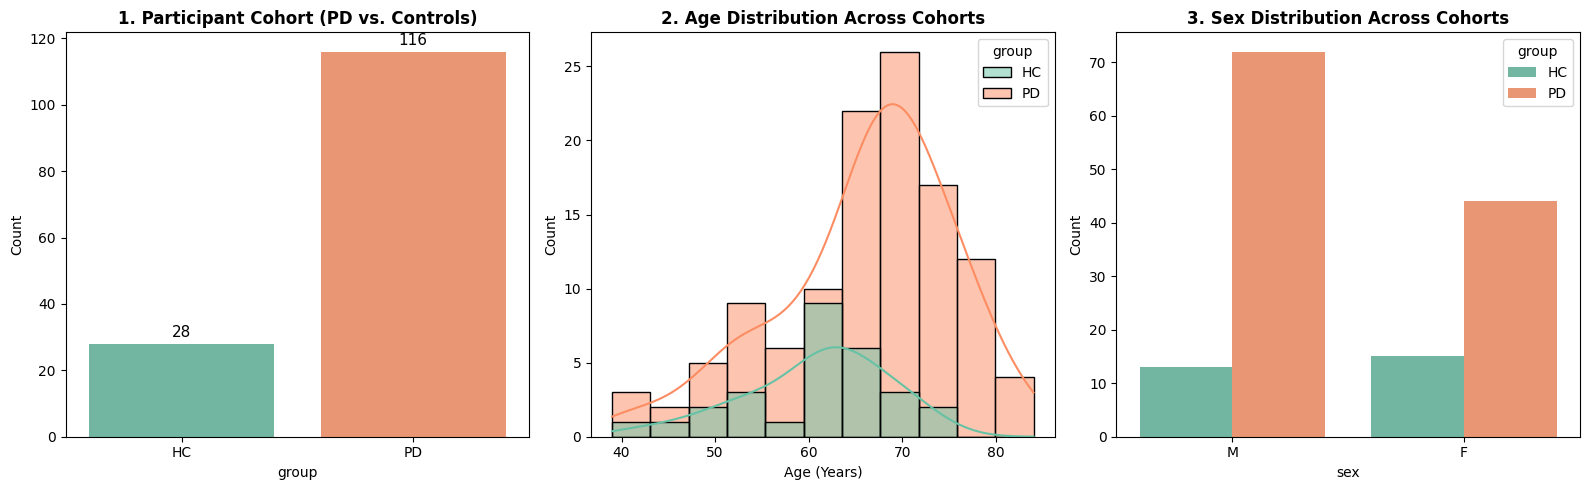

✅ Clinical demographics plot saved as: clinical_demographics.png


In [3]:
participants_file = os.path.join(bids_root, "participants.tsv")

if os.path.exists(participants_file):
    df_part = pd.read_csv(participants_file, sep="\t")
    print("=== Participants Overview ===")
    display(df_part.head(10))
    
    # Save demographic summary
    df_part.to_csv(os.path.join(OUTPUT_DIR, "participants_demographics.csv"), index=False)
    
    # Plot Demographic Distribution
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    # 1. Group Distribution (PD vs Control)
    if "group" in df_part.columns:
        sns.countplot(data=df_part, x="group", ax=axes[0], palette="Set2")
        axes[0].set_title("1. Participant Cohort (PD vs. Controls)", fontsize=12, fontweight='bold')
        axes[0].set_ylabel("Count")
        for p in axes[0].patches:
            axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                             ha='center', va='baseline', fontsize=11, xytext=(0, 5), textcoords='offset points')
    
    # 2. Age Distribution
    if "age" in df_part.columns:
        sns.histplot(data=df_part, x="age", hue="group" if "group" in df_part.columns else None,
                     kde=True, ax=axes[1], palette="Set2")
        axes[1].set_title("2. Age Distribution Across Cohorts", fontsize=12, fontweight='bold')
        axes[1].set_xlabel("Age (Years)")
        
    # 3. Sex Distribution
    if "sex" in df_part.columns:
        sns.countplot(data=df_part, x="sex", hue="group" if "group" in df_part.columns else None,
                      ax=axes[2], palette="Set2")
        axes[2].set_title("3. Sex Distribution Across Cohorts", fontsize=12, fontweight='bold')
        axes[2].set_ylabel("Count")
        
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "clinical_demographics.png"), dpi=300)
    plt.show()
    print("✅ Clinical demographics plot saved as: clinical_demographics.png")
else:
    print("⚠️ participants.tsv file not found in root directory.")


## 4. Complete Dataset Inventory & Recording Audit
সবকটি ফাইলের চ্যানেল সংখ্যা, স্যাম্পলিং রেট এবং রেকর্ডিং সময় পরীক্ষা।


Scanning all recording sessions (this may take ~20-30 seconds)...

✅ Total Subjects Identified: 144
✅ Total Recordings Inventory:
task
Rest    144
Walk    133
Name: count, dtype: int64


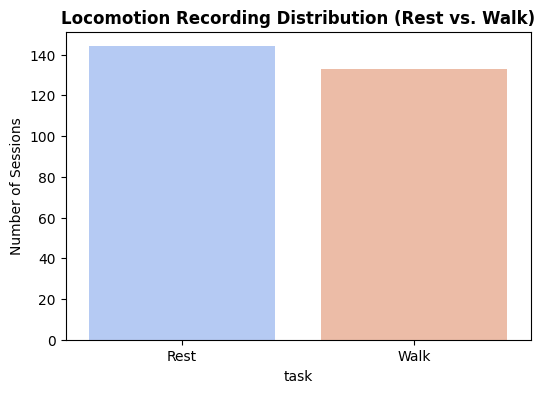

In [4]:
records_info = []

print("Scanning all recording sessions (this may take ~20-30 seconds)...")
for f in all_set_files:
    fname = os.path.basename(f)
    task = "Walk" if "task-walk" in fname.lower() else ("Rest" if "task-rest" in fname.lower() else "Other")
    sub_id = fname.split("_")[0]
    
    records_info.append({
        "filename": fname,
        "subject_id": sub_id,
        "task": task,
        "filepath": f
    })

df_inventory = pd.DataFrame(records_info)
df_inventory.to_csv(os.path.join(OUTPUT_DIR, "dataset_inventory.csv"), index=False)

print(f"\n✅ Total Subjects Identified: {df_inventory['subject_id'].nunique()}")
print(f"✅ Total Recordings Inventory:\n{df_inventory['task'].value_counts()}")

# Bar chart of task distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_inventory, x="task", palette="coolwarm")
plt.title("Locomotion Recording Distribution (Rest vs. Walk)", fontweight='bold')
plt.ylabel("Number of Sessions")
plt.savefig(os.path.join(OUTPUT_DIR, "task_distribution.png"), dpi=300)
plt.show()


## 5. Channel Array & Sensor Topography (10-20 System)
মস্তিষ্কের ৬০টি ইলেকট্রোড ও ৪টি চোখের চ্যানেলের অবস্থান ভিজ্যুয়ালাইজেশন।


Inspecting sensor array using: sub-093_task-rest_eeg.set
• Total Channels in Raw File: 65
• Sampling Frequency: 250.0 Hz
• Total Duration: 240.94 seconds

Channel Categorization:
   • Scalp EEG Channels (60): ['F10', 'AF4', 'F2', 'FCz', 'Fp2', 'Fz', 'FC1', 'AFz'] ...
   • Ocular EOG Channels (4): ['EOG1', 'EOG2', 'EOG3', 'EOG4']
   • Reference Channels (1): ['VREF']


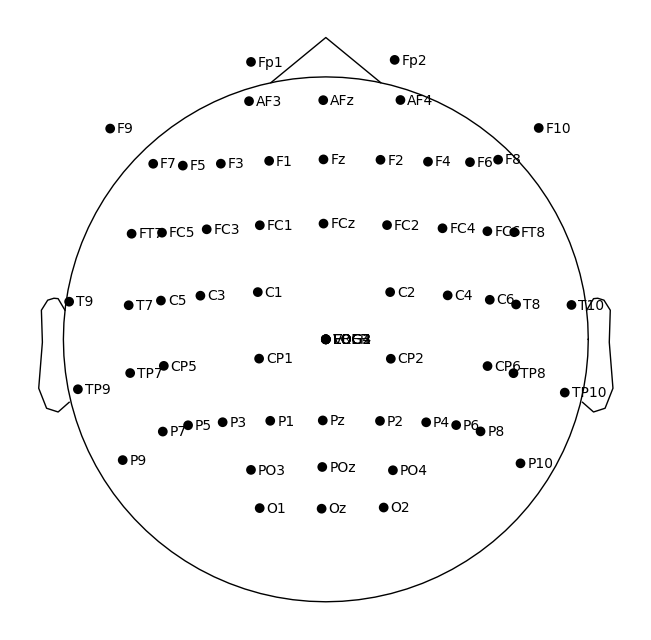

<Figure size 640x480 with 0 Axes>

✅ Sensor Layout Topomap saved as: eeg_sensor_layout.png


In [5]:
# Load one representative raw EEG file
sample_file = all_set_files[0]
print(f"Inspecting sensor array using: {os.path.basename(sample_file)}")

raw_sample = mne.io.read_raw_eeglab(sample_file, preload=True, verbose=False)

print(f"• Total Channels in Raw File: {len(raw_sample.ch_names)}")
print(f"• Sampling Frequency: {raw_sample.info['sfreq']} Hz")
print(f"• Total Duration: {raw_sample.times[-1]:.2f} seconds")

# Categorize Channels
eog_channels = [ch for ch in ['EOG1', 'EOG2', 'EOG3', 'EOG4'] if ch in raw_sample.ch_names]
ref_channels = [ch for ch in ['VREF'] if ch in raw_sample.ch_names]
eeg_channels = [ch for ch in raw_sample.ch_names if ch not in eog_channels and ch not in ref_channels]

print(f"\nChannel Categorization:")
print(f"   • Scalp EEG Channels ({len(eeg_channels)}): {eeg_channels[:8]} ...")
print(f"   • Ocular EOG Channels ({len(eog_channels)}): {eog_channels}")
print(f"   • Reference Channels ({len(ref_channels)}): {ref_channels}")

# Assign Standard 10-20 Montage
montage = mne.channels.make_standard_montage("standard_1020")
raw_sample.set_montage(montage, on_missing='ignore')

# Plot 2D Sensor Topography Layout
fig = raw_sample.plot_sensors(show_names=True, title="60-Channel Scalp EEG Sensor Layout")
plt.savefig(os.path.join(OUTPUT_DIR, "eeg_sensor_layout.png"), dpi=300)
plt.show()
print("✅ Sensor Layout Topomap saved as: eeg_sensor_layout.png")


## 6. Raw Signal Time-Series Comparison: Rest vs. Walk
হাঁটা বনাম রেস্ট অবস্থায় মস্তিষ্কের সিগন্যালের প্রত্যক্ষ ভিজ্যুয়াল তুলনা (মোশন ও আই-ব্লিঙ্ক আর্টফ্যাক্ট প্রদর্শন)।


Comparing Subject: sub-093
   Rest: sub-093_task-rest_eeg.set
   Walk: sub-093_task-walk_eeg.set


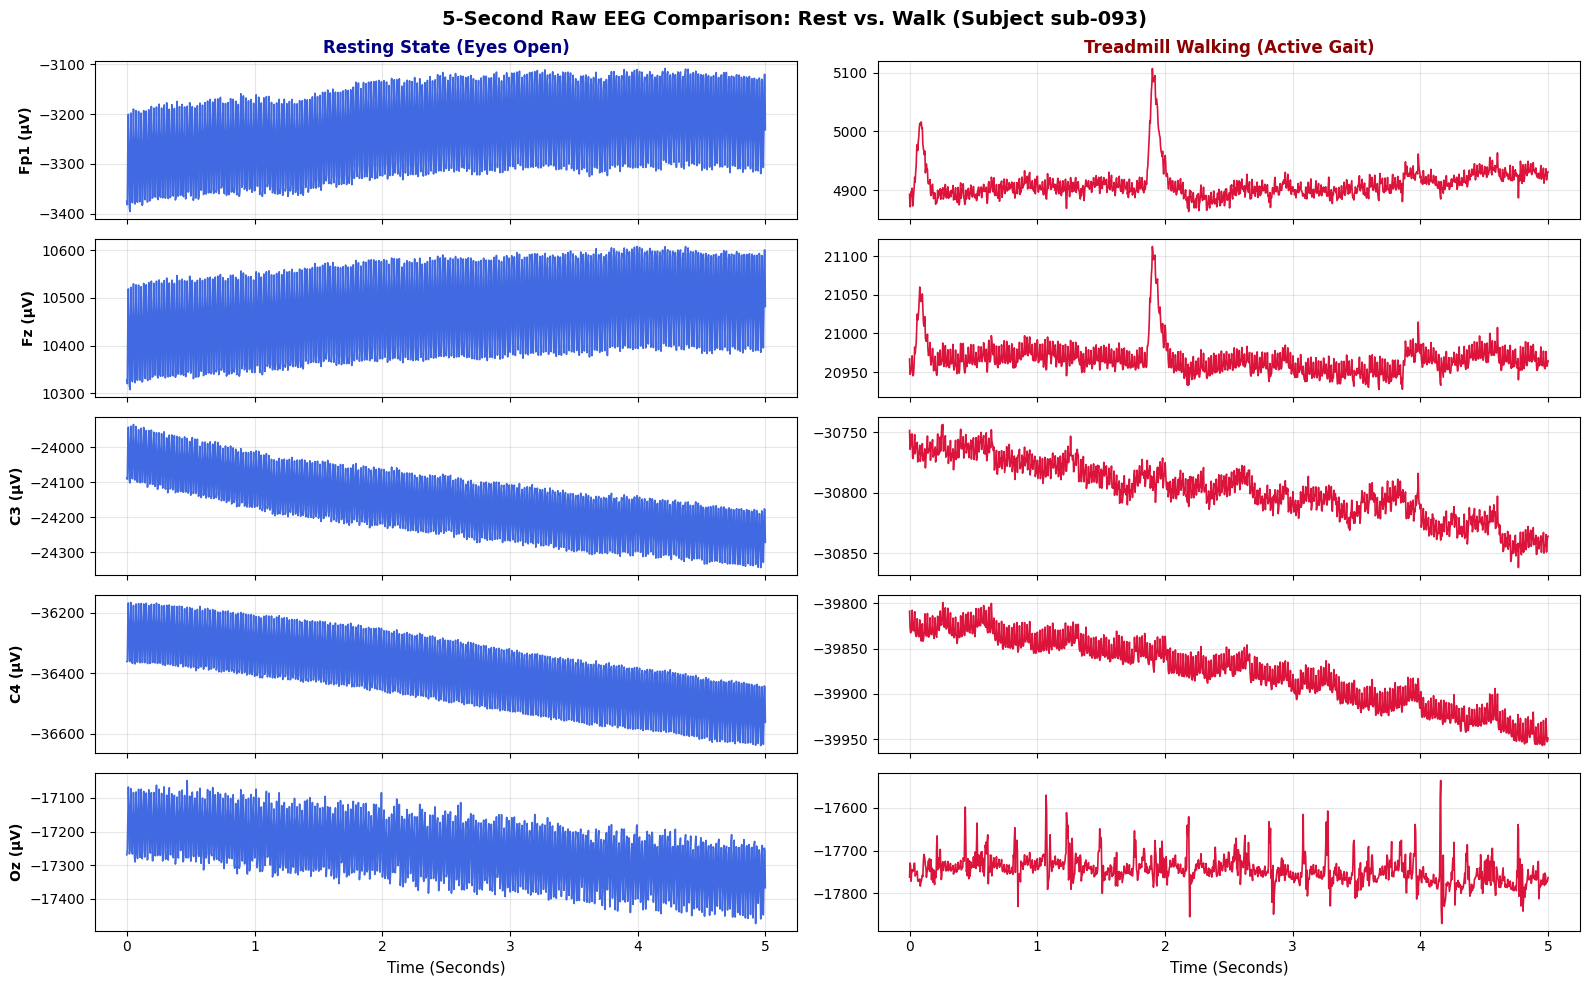

✅ Time-series comparison plot saved as: raw_signal_rest_vs_walk.png


In [6]:
# Pick the first subject that has both Rest and Walk recordings
sample_sub = df_inventory['subject_id'].iloc[0]
sub_rest_file = df_inventory[(df_inventory['subject_id'] == sample_sub) & (df_inventory['task'] == "Rest")]['filepath'].iloc[0]
sub_walk_file = df_inventory[(df_inventory['subject_id'] == sample_sub) & (df_inventory['task'] == "Walk")]['filepath'].iloc[0]

print(f"Comparing Subject: {sample_sub}")
print(f"   Rest: {os.path.basename(sub_rest_file)}")
print(f"   Walk: {os.path.basename(sub_walk_file)}")

raw_r = mne.io.read_raw_eeglab(sub_rest_file, preload=True, verbose=False)
raw_w = mne.io.read_raw_eeglab(sub_walk_file, preload=True, verbose=False)

# Select 6 key channels (Frontal, Central Motor: Cz, C3, C4, Occipital)
selected_channels = [ch for ch in ['Fp1', 'Fz', 'C3', 'Cz', 'C4', 'Oz'] if ch in raw_r.ch_names]
if len(selected_channels) < 4:
    selected_channels = raw_r.ch_names[:6]

time_window = 5.0 # 5 seconds
sfreq = int(raw_r.info['sfreq'])
n_samples = int(time_window * sfreq)
t = np.linspace(0, time_window, n_samples)

data_r, _ = raw_r[selected_channels, :n_samples]
data_w, _ = raw_w[selected_channels, :n_samples]

fig, axes = plt.subplots(len(selected_channels), 2, figsize=(16, 10), sharex=True)
fig.suptitle(f"5-Second Raw EEG Comparison: Rest vs. Walk (Subject {sample_sub})", fontsize=14, fontweight='bold')

for i, ch in enumerate(selected_channels):
    # Rest Signal
    axes[i, 0].plot(t, data_r[i] * 1e6, color='royalblue', lw=1.2)
    axes[i, 0].set_ylabel(f"{ch} (µV)", fontsize=10, fontweight='bold')
    axes[i, 0].grid(True, alpha=0.3)
    if i == 0:
        axes[i, 0].set_title("Resting State (Eyes Open)", fontsize=12, fontweight='bold', color='navy')
    
    # Walk Signal
    axes[i, 1].plot(t, data_w[i] * 1e6, color='crimson', lw=1.2)
    axes[i, 1].grid(True, alpha=0.3)
    if i == 0:
        axes[i, 1].set_title("Treadmill Walking (Active Gait)", fontsize=12, fontweight='bold', color='darkred')

axes[-1, 0].set_xlabel("Time (Seconds)", fontsize=11)
axes[-1, 1].set_xlabel("Time (Seconds)", fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "raw_signal_rest_vs_walk.png"), dpi=300)
plt.show()
print("✅ Time-series comparison plot saved as: raw_signal_rest_vs_walk.png")


## 7. Spectral & Frequency Bandpower Analysis (PSD)
৫টি ব্রেনওয়েভ ব্যান্ডের (Delta, Theta, Alpha, Beta, Gamma) পাওয়ার অ্যানালাইসিস।


,Band,Rest_Power,Walk_Power,Walk_to_Rest_Ratio
0,Delta (0.5-4 Hz),2.527740e-11,2.855444e-11,1.129598
1,Theta (4-8 Hz),1.829535e-12,6.673963e-12,3.645909
2,Alpha (8-13 Hz),1.357254e-12,2.783184e-12,2.049089
3,Beta (13-30 Hz),7.892011e-13,1.367586e-12,1.730681
4,Gamma (30-45 Hz),3.107874e-13,7.011014e-13,2.248652


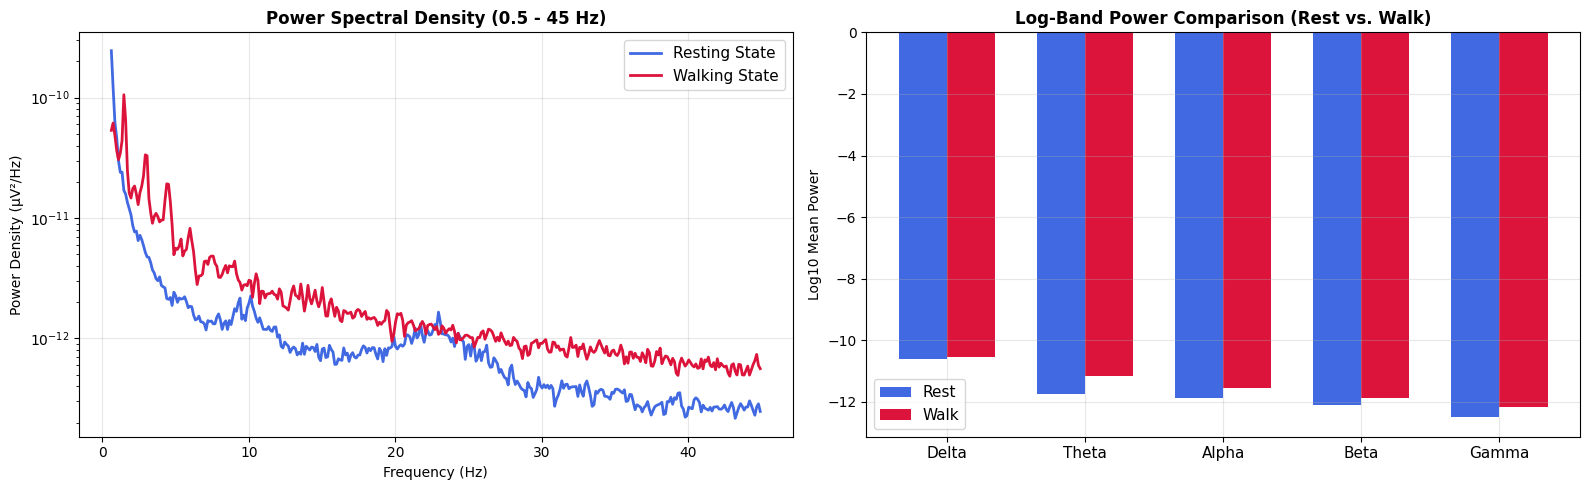

✅ Bandpower comparison saved as: psd_bandpower_comparison.png


In [7]:
bands = {
    "Delta (0.5-4 Hz)": (0.5, 4.0),
    "Theta (4-8 Hz)": (4.0, 8.0),
    "Alpha (8-13 Hz)": (8.0, 13.0),
    "Beta (13-30 Hz)": (13.0, 30.0),
    "Gamma (30-45 Hz)": (30.0, 45.0)
}

# Compute Power Spectral Density (PSD) using Welch method
psd_r = raw_r.compute_psd(fmin=0.5, fmax=45.0, verbose=False)
psd_w = raw_w.compute_psd(fmin=0.5, fmax=45.0, verbose=False)

freqs = psd_r.freqs
powers_r = psd_r.get_data().mean(axis=0) # Mean across all channels
powers_w = psd_w.get_data().mean(axis=0)

# Compute Band Powers
band_summary = []
for b_name, (fmin, fmax) in bands.items():
    idx = (freqs >= fmin) & (freqs <= fmax)
    p_r = powers_r[idx].mean()
    p_w = powers_w[idx].mean()
    band_summary.append({
        "Band": b_name,
        "Rest_Power": p_r,
        "Walk_Power": p_w,
        "Walk_to_Rest_Ratio": p_w / (p_r + 1e-15)
    })

df_bands = pd.DataFrame(band_summary)
display(df_bands)
df_bands.to_csv(os.path.join(OUTPUT_DIR, "bandpower_comparison.csv"), index=False)

# Visualization of Spectral Characteristics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Continuous PSD Spectrum
ax1.semilogy(freqs, powers_r, label="Resting State", color='royalblue', lw=2)
ax1.semilogy(freqs, powers_w, label="Walking State", color='crimson', lw=2)
ax1.set_title("Power Spectral Density (0.5 - 45 Hz)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Frequency (Hz)")
ax1.set_ylabel("Power Density (µV²/Hz)")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=11)

# 2. Relative Band Power Bar Chart
x = np.arange(len(df_bands))
width = 0.35
ax2.bar(x - width/2, np.log10(df_bands["Rest_Power"]), width, label="Rest", color='royalblue')
ax2.bar(x + width/2, np.log10(df_bands["Walk_Power"]), width, label="Walk", color='crimson')
ax2.set_xticks(x)
ax2.set_xticklabels([b.split()[0] for b in df_bands["Band"]], fontsize=11)
ax2.set_title("Log-Band Power Comparison (Rest vs. Walk)", fontsize=12, fontweight='bold')
ax2.set_ylabel("Log10 Mean Power")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "psd_bandpower_comparison.png"), dpi=300)
plt.show()
print("✅ Bandpower comparison saved as: psd_bandpower_comparison.png")


## 8. Channel Correlation Matrix & Sensor Quality Check
ইলেকট্রোডগুলোর পারস্পরিক কোরিলেশন এবং নষ্ট/ফ্ল্যাট চ্যানেল ডিটেকশন।


Dead / Flat Channels Detected: 1
Dead Channels: ['VREF']


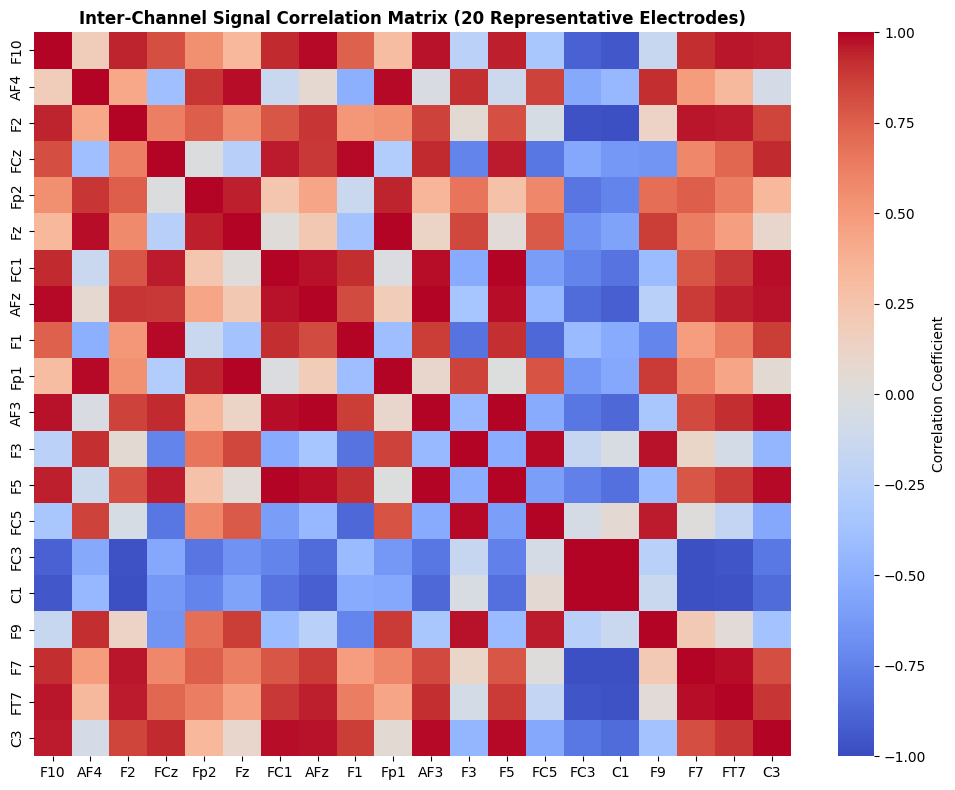

✅ Channel correlation heatmap saved as: channel_correlation_matrix.png


In [8]:
# Compute channel standard deviations
data = raw_r.get_data()
ch_stds = np.std(data, axis=1)

dead_channels = [raw_r.ch_names[i] for i, s in enumerate(ch_stds) if s < 1e-12]
print(f"Dead / Flat Channels Detected: {len(dead_channels)}")
if dead_channels:
    print(f"Dead Channels: {dead_channels}")
else:
    print("✅ No dead channels found across the tested session!")

# Channel Correlation Heatmap (using 20 scalp electrodes for clarity)
sample_subset = data[:20, :2500]
corr_matrix = np.corrcoef(sample_subset)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, xticklabels=raw_r.ch_names[:20], yticklabels=raw_r.ch_names[:20],
            cmap="coolwarm", vmin=-1, vmax=1, cbar_kws={'label': 'Correlation Coefficient'})
plt.title("Inter-Channel Signal Correlation Matrix (20 Representative Electrodes)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "channel_correlation_matrix.png"), dpi=300)
plt.show()
print("✅ Channel correlation heatmap saved as: channel_correlation_matrix.png")


## 9. Executive Insight Summary & Export Manifest
জেনারেট হওয়া সব ফিগার এবং টেবিলের তালিকা।


In [9]:
print("=" * 65)
print("🎯 AUTOMATED DATASET INSIGHT & EDA COMPLETED SUCCESSFULLY!")
print("=" * 65)

output_files = os.listdir(OUTPUT_DIR)
print(f"\n📁 Files Saved in '{OUTPUT_DIR}':")
for f in sorted(output_files):
    fpath = os.path.join(OUTPUT_DIR, f)
    size_kb = os.path.getsize(fpath) / 1024
    print(f"   • {f} ({size_kb:.1f} KB)")

print("\n💡 পরবর্তী করণীয় (Next Step):")
print("১. এই গ্রাফ ও টেবিলগুলো আপনার পেপারের 'Section 3: Dataset & EDA'-তে হুবহু ব্যবহার করতে পারবেন।")
print("২. এরপরে আমরা 'Model Training & Evaluation' স্ক্রিপ্টটি রান করাব যা CSP, RF, XGBoost এবং EEGNet ট্রেন করবে।")


🎯 AUTOMATED DATASET INSIGHT & EDA COMPLETED SUCCESSFULLY!

📁 Files Saved in '/kaggle/working/dataset_insights':
   • bandpower_comparison.csv (0.4 KB)
   • channel_correlation_matrix.png (151.3 KB)
   • clinical_demographics.png (201.0 KB)
   • dataset_inventory.csv (33.0 KB)
   • eeg_sensor_layout.png (13.9 KB)
   • participants_demographics.csv (9.2 KB)
   • psd_bandpower_comparison.png (314.0 KB)
   • raw_signal_rest_vs_walk.png (1520.2 KB)
   • task_distribution.png (69.4 KB)

💡 পরবর্তী করণীয় (Next Step):
১. এই গ্রাফ ও টেবিলগুলো আপনার পেপারের 'Section 3: Dataset & EDA'-তে হুবহু ব্যবহার করতে পারবেন।
২. এরপরে আমরা 'Model Training & Evaluation' স্ক্রিপ্টটি রান করাব যা CSP, RF, XGBoost এবং EEGNet ট্রেন করবে।
